# 🎮 Modul 11 — Praktikum Sampling Distribution & Confidence Interval

### A/B Testing at Scale: Cookie Cats — 90.189 Pemain Game Mobile

**Mata Kuliah:** Statistika & Probabilitas (TIF1501)
**Program Studi:** Teknik Informatika (55201) · FTI · Uniska MAB Banjarmasin
**Semester:** 5 · 3 SKS · CPMK072 (Sub-CPMK 072.2) · Milestone 3

---

## 🎯 Tujuan Pembelajaran

1. **Memahami** sampling distribution dan Standard Error melalui simulasi.
2. **Menghitung** CI untuk proporsi, selisih dua proporsi, dan bootstrap CI.
3. **Melakukan** power analysis untuk menentukan sample size sebelum eksperimen.
4. **Mengenali** jebakan A/B testing skala besar: SRM, peeking, banyak metrik.

---

## 📋 Alur Notebook

| Bagian | Isi | Waktu |
|--------|-----|-------|
| **A** | Setup & Load Cookie Cats | 5 menit |
| **B** | EDA & Outlier | 10 menit |
| **C** | Simulasi Sampling Distribution & SE | 15 menit |
| **D** | CI Proporsi, Selisih & Bootstrap | 15 menit |
| **E** | z-test & SRM Check | 10 menit |
| **F** | Power Analysis & Sample Size | 10 menit |
| **G** | Simulasi Peeking Problem | 10 menit |
| **H** | Template Milestone 3 + Refleksi | 15 menit |

**Total: ± 90 menit**

---

## 💡 Konteks Eksperimen

**Cookie Cats** adalah game puzzle mobile. Pada level tertentu pemain menemui **gerbang** — harus menunggu atau membeli in-app purchase untuk lanjut. Developer menjalankan A/B test:

- **gate_30** (kontrol): gerbang di level 30
- **gate_40** (treatment): gerbang dipindah ke level 40

**Pertanyaan bisnis**: apakah memindahkan gerbang ke level 40 mengubah retensi pemain?

| Kolom | Arti |
|---|---|
| `userid` | ID pemain |
| `version` | grup eksperimen (gate_30 / gate_40) |
| `sum_gamerounds` | jumlah ronde dimainkan dalam 14 hari pertama |
| `retention_1` | kembali main 1 hari setelah install? (True/False) |
| `retention_7` | kembali main 7 hari setelah install? (True/False) |


---

# 🔧 A. Setup & Load Dataset


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
rng = np.random.default_rng(42)
ALPHA = 0.05
COLORS = {'gate_30': '#0284C7', 'gate_40': '#D97706'}

url = "https://raw.githubusercontent.com/ryanschaub/Mobile-Games-A-B-Testing-with-Cookie-Cats/master/cookie_cats.csv"
df = pd.read_csv(url)
for col in ['retention_1', 'retention_7']:
    df[col] = df[col].astype(int)   # True/False → 1/0 (Bernoulli)

A = df[df.version == 'gate_30']   # kontrol
B = df[df.version == 'gate_40']   # treatment
print(f"Total pemain : {len(df):,}")
print(f"gate_30      : {len(A):,}")
print(f"gate_40      : {len(B):,}")
df.head()


---

# 🔍 B. EDA & Outlier


In [ ]:
summary = df.groupby('version').agg(
    n=('userid', 'count'),
    retensi_1=('retention_1', 'mean'),
    retensi_7=('retention_7', 'mean'),
    ronde_mean=('sum_gamerounds', 'mean'),
    ronde_median=('sum_gamerounds', 'median'),
    ronde_max=('sum_gamerounds', 'max'),
)
summary[['retensi_1', 'retensi_7']] = (summary[['retensi_1', 'retensi_7']] * 100).round(2)
print("Retensi dalam persen:")
summary.round(2)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(df['sum_gamerounds'], bins=100, color='#0284C7', edgecolor='black')
axes[0].set_title('sum_gamerounds — semua data (outlier merusak skala!)', fontweight='bold')
axes[0].set_xlabel('ronde')

clip = df[df.sum_gamerounds <= df.sum_gamerounds.quantile(0.99)]
for v, d in clip.groupby('version'):
    axes[1].hist(d['sum_gamerounds'], bins=60, alpha=0.55, color=COLORS[v], label=v)
axes[1].set_title('sum_gamerounds ≤ persentil 99', fontweight='bold')
axes[1].set_xlabel('ronde'); axes[1].legend()
plt.tight_layout(); plt.show()

top = df.nlargest(3, 'sum_gamerounds')[['userid', 'version', 'sum_gamerounds']]
print("3 pemain dengan ronde terbanyak:"); print(top.to_string(index=False))
print(f"\nPersentil 99 = {df.sum_gamerounds.quantile(0.99):.0f} ronde, tetapi maks = {df.sum_gamerounds.max():,} ronde.")
print("💡 Distribusi sangat skewed — mean mudah ditarik outlier, median lebih stabil.")


---

# 📐 C. Simulasi Sampling Distribution & Standard Error

**Tujuan Pembelajaran 1.** Kita anggap **seluruh 90.189 pemain sebagai populasi**, sehingga parameter populasinya diketahui. Lalu kita ambil sampel berulang kali dan amati distribusi statistiknya.

## C.1 Sampling distribution proporsi (retensi-7)

Teori: $SE(\hat{p}) = \sqrt{p(1-p)/n}$


In [ ]:
pop_r7 = df['retention_7'].values
p_true = pop_r7.mean()
REPS = 2000

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
rows = []
for ax, n in zip(axes, [100, 1_000, 10_000]):
    p_hats = rng.choice(pop_r7, size=(REPS, n), replace=True).mean(axis=1)
    se_theory = np.sqrt(p_true * (1 - p_true) / n)
    rows.append([n, p_hats.std(), se_theory])
    ax.hist(p_hats, bins=40, density=True, color='#0284C7', edgecolor='black', alpha=0.7)
    xs = np.linspace(p_true - 4*se_theory, p_true + 4*se_theory, 200)
    ax.plot(xs, stats.norm.pdf(xs, p_true, se_theory), 'r-', lw=2, label='Normal teori (CLT)')
    ax.axvline(p_true, color='black', ls='--')
    ax.set_title(f'n = {n:,}  →  SE = {se_theory:.4f}', fontweight='bold')
    ax.set_xlabel('p̂ (retensi-7)'); ax.legend(fontsize=9)
plt.suptitle(f'Sampling distribution p̂ dari {REPS} sampel — p populasi = {p_true:.4f}', y=1.03, fontweight='bold')
plt.tight_layout(); plt.show()

print(pd.DataFrame(rows, columns=['n', 'SE empiris', 'SE teori']).round(5).to_string(index=False))
print("\n💡 n naik 10× → SE turun √10 ≈ 3.16×. Untuk SE setengahnya, butuh 4× data.")


## C.2 Sampling distribution mean pada data sangat skewed (sum_gamerounds)

CLT tetap berlaku, tetapi **butuh n lebih besar** jika data sangat skewed.


In [ ]:
pop_rounds = df['sum_gamerounds'].values
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, n in zip(axes, [30, 300, 3_000]):
    means = rng.choice(pop_rounds, size=(REPS, n), replace=True).mean(axis=1)
    ax.hist(means, bins=50, color='#D97706', edgecolor='black', alpha=0.75)
    ax.axvline(pop_rounds.mean(), color='black', ls='--', label=f'μ = {pop_rounds.mean():.1f}')
    ax.set_title(f'n = {n:,} | skewness x̄ = {stats.skew(means):.2f}', fontweight='bold')
    ax.set_xlabel('x̄ ronde'); ax.legend(fontsize=9)
plt.suptitle('Sampling distribution x̄ sum_gamerounds — makin besar n, makin simetris', y=1.03, fontweight='bold')
plt.tight_layout(); plt.show()
print("💡 Skewness mendekati 0 = makin mirip Normal. Pada n kecil, satu outlier bisa menggeser x̄ drastis.")


---

# 📏 D. Confidence Interval: Proporsi, Selisih & Bootstrap

**Tujuan Pembelajaran 2.**

## D.1 CI proporsi per grup — Wald vs Wilson


In [ ]:
rows = []
for metric in ['retention_1', 'retention_7']:
    for name, g in [('gate_30', A), ('gate_40', B)]:
        k, n = g[metric].sum(), len(g)
        wald = proportion_confint(k, n, alpha=ALPHA, method='normal')
        wilson = proportion_confint(k, n, alpha=ALPHA, method='wilson')
        rows.append([metric, name, k/n*100, wald[0]*100, wald[1]*100, wilson[0]*100, wilson[1]*100])
ci_table = pd.DataFrame(rows, columns=['metrik', 'grup', 'p̂ %', 'Wald lo', 'Wald hi', 'Wilson lo', 'Wilson hi']).round(2)
print(ci_table.to_string(index=False))
print("\n💡 Dengan n ≈ 45.000, Wald dan Wilson praktis identik.")
print("   Perbedaan baru terasa saat n kecil atau p mendekati 0/1 (misal conversion rate 0.5%).")


## D.2 CI selisih proporsi (gate_30 − gate_40)

$$(\hat{p}_A - \hat{p}_B) \pm 1.96 \sqrt{\frac{\hat{p}_A(1-\hat{p}_A)}{n_A} + \frac{\hat{p}_B(1-\hat{p}_B)}{n_B}}$$


In [ ]:
def ci_diff_prop(a, b, alpha=ALPHA):
    pa, pb = a.mean(), b.mean()
    se = np.sqrt(pa*(1-pa)/len(a) + pb*(1-pb)/len(b))
    z = stats.norm.ppf(1 - alpha/2)
    d = pa - pb
    return d, se, d - z*se, d + z*se

diff_rows = []
for metric in ['retention_1', 'retention_7']:
    d, se, lo, hi = ci_diff_prop(A[metric], B[metric])
    diff_rows.append([metric, d*100, se*100, lo*100, hi*100, 'Ya' if lo > 0 or hi < 0 else 'Tidak (memuat 0)'])
diff_table = pd.DataFrame(diff_rows, columns=['metrik', 'selisih (poin %)', 'SE', 'CI lo', 'CI hi', 'Signifikan?']).round(3)
print(diff_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 2.8))
for i, r in diff_table.iterrows():
    color = '#059669' if r['Signifikan?'] == 'Ya' else '#64748B'
    ax.plot([r['CI lo'], r['CI hi']], [i, i], color=color, lw=6)
    ax.plot(r['selisih (poin %)'], i, 'o', color='black', ms=8)
ax.axvline(0, color='#E11D48', ls='--', lw=2)
ax.set_yticks([0, 1]); ax.set_yticklabels(diff_table['metrik'])
ax.set_xlabel('selisih gate_30 − gate_40 (poin persen)')
ax.set_title('CI 95% selisih retensi', fontweight='bold')
plt.tight_layout(); plt.show()


## D.3 Bootstrap CI

Bootstrap tidak butuh rumus SE. Kita pakai untuk:
1. **Selisih retensi-7** — membandingkan dengan CI rumus di atas
2. **Selisih median ronde** — metrik yang tidak punya rumus SE sederhana


In [ ]:
B_REPS = 2000
a7, b7 = A['retention_7'].values, B['retention_7'].values
ar, br = A['sum_gamerounds'].values, B['sum_gamerounds'].values

boot_r7, boot_med = np.empty(B_REPS), np.empty(B_REPS)
for i in range(B_REPS):
    ia = rng.integers(0, len(a7), len(a7))
    ib = rng.integers(0, len(b7), len(b7))
    boot_r7[i] = a7[ia].mean() - b7[ib].mean()
    boot_med[i] = np.median(ar[ia]) - np.median(br[ib])

lo7, hi7 = np.percentile(boot_r7, [2.5, 97.5])
_, _, flo, fhi = ci_diff_prop(A['retention_7'], B['retention_7'])
print("=== SELISIH RETENSI-7 (gate_30 − gate_40) ===")
print(f"  Bootstrap CI 95% : [{lo7*100:.3f}, {hi7*100:.3f}] poin %")
print(f"  Rumus (Wald)     : [{flo*100:.3f}, {fhi*100:.3f}] poin %")
print(f"  P(selisih > 0) dari bootstrap = {(boot_r7 > 0).mean():.3f}")

lom, him = np.percentile(boot_med, [2.5, 97.5])
print("\n=== SELISIH MEDIAN RONDE (gate_30 − gate_40) ===")
print(f"  Median gate_30 = {np.median(ar):.0f}, gate_40 = {np.median(br):.0f}")
print(f"  Bootstrap CI 95% : [{lom:.1f}, {him:.1f}] ronde")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(boot_r7*100, bins=50, color='#7C3AED', edgecolor='black', alpha=0.75)
for v in [lo7*100, hi7*100]: axes[0].axvline(v, color='black', ls='--')
axes[0].axvline(0, color='#E11D48', lw=2, label='0 (tidak ada efek)')
axes[0].set_title('Bootstrap selisih retensi-7 (poin %)', fontweight='bold'); axes[0].legend()
axes[1].hist(boot_med, bins=np.arange(boot_med.min()-0.5, boot_med.max()+1.5, 1), color='#0D9488', edgecolor='black', alpha=0.75)
axes[1].axvline(0, color='#E11D48', lw=2)
axes[1].set_title('Bootstrap selisih median ronde', fontweight='bold')
plt.tight_layout(); plt.show()
print("💡 Distribusi bootstrap median 'bergerigi' karena median data diskret selalu bilangan bulat/setengah.")


---

# 🧪 E. z-test & Sample Ratio Mismatch (SRM) Check

## E.1 SRM check — LAKUKAN INI PERTAMA

Alokasi direncanakan 50:50. Jika rasio teramati menyimpang signifikan, kemungkinan ada **bug** pada randomisasi atau logging — dan semua hasil eksperimen jadi diragukan.

**H₀**: rasio alokasi = 50:50 (uji chi-square goodness-of-fit)


In [ ]:
observed = [len(A), len(B)]
expected = [len(df) / 2] * 2
chi2, p_srm = stats.chisquare(observed, expected)

print("=== SRM CHECK ===")
print(f"  Observed : gate_30 = {observed[0]:,} ({observed[0]/len(df)*100:.2f}%), gate_40 = {observed[1]:,} ({observed[1]/len(df)*100:.2f}%)")
print(f"  Expected : {expected[0]:,.0f} per grup")
print(f"  χ² = {chi2:.3f}, p = {p_srm:.4f}")
if p_srm < 0.001:
    print("  🚨 SRM kuat — hentikan analisis, investigasi pipeline alokasi.")
elif p_srm < ALPHA:
    print("  ⚠️  Ada indikasi SRM (p < 0.05). Banyak tim memakai ambang lebih ketat (mis. p < 0.001)")
    print("     karena SRM check dijalankan terus-menerus. Catat sebagai risiko & cek ke tim engineering.")
else:
    print("  ✅ Tidak ada indikasi SRM.")
print("\n💡 Selisih 789 pemain terdengar kecil, tetapi pada skala 90.000 sudah terdeteksi oleh uji.")


## E.2 Two-proportion z-test

**H₀**: p_gate30 = p_gate40  **H₁**: p_gate30 ≠ p_gate40


In [ ]:
test_rows = []
for metric in ['retention_1', 'retention_7']:
    counts = np.array([A[metric].sum(), B[metric].sum()])
    nobs = np.array([len(A), len(B)])
    z, p = proportions_ztest(counts, nobs)
    h = proportion_effectsize(counts[0]/nobs[0], counts[1]/nobs[1])
    test_rows.append([metric, counts[0]/nobs[0]*100, counts[1]/nobs[1]*100, z, p, h,
                      'Tolak H₀' if p < ALPHA else 'Gagal tolak H₀'])
tests = pd.DataFrame(test_rows, columns=['metrik', 'gate_30 %', 'gate_40 %', 'z', 'p-value', "Cohen's h", 'Keputusan'])
print(tests.round(4).to_string(index=False))
print("\n💡 Cohen's h ≈ 0.02 → efek SANGAT kecil secara standar statistik,")
print("   tetapi untuk game dengan jutaan pemain, 0.8 poin retensi bisa berarti banyak pemain & pendapatan.")


---

# ⚡ F. Power Analysis & Sample Size

**Tujuan Pembelajaran 3.** Berapa pemain yang dibutuhkan untuk mendeteksi efek tertentu dengan α = 0.05 dan power = 0.80?


In [ ]:
power = NormalIndPower()

def n_needed(p_base, mde_pts, alpha=ALPHA, pw=0.80):
    es = proportion_effectsize(p_base, p_base - mde_pts/100)
    return power.solve_power(effect_size=abs(es), alpha=alpha, power=pw, ratio=1.0)

base_r1, base_r7 = A['retention_1'].mean(), A['retention_7'].mean()
print("=== SAMPLE SIZE PER GRUP (α=0.05, power=0.80) ===")
for mde in [2.0, 1.0, 0.82, 0.59, 0.25]:
    print(f"  MDE {mde:>4} poin (retensi-7 base {base_r7*100:.1f}%) → n ≈ {n_needed(base_r7, mde):>10,.0f}")

n_r1 = n_needed(base_r1, 0.59)
achieved = power.solve_power(effect_size=abs(proportion_effectsize(base_r1, B['retention_1'].mean())),
                             nobs1=len(A), alpha=ALPHA, ratio=len(B)/len(A))
print(f"\nRetensi-1: selisih teramati 0.59 poin butuh ≈ {n_r1:,.0f} per grup.")
print(f"Tersedia ≈ {len(A):,} per grup → power yang dicapai hanya ≈ {achieved:.0%}.")
print("💡 Retensi-1 'tidak signifikan' bukan bukti tidak ada efek — eksperimennya UNDERPOWERED.")


In [ ]:
mdes = np.linspace(0.3, 3.0, 60)
fig, ax = plt.subplots(figsize=(11, 5))
for base, label, color in [(base_r1, f'retensi-1 (base {base_r1*100:.1f}%)', '#0284C7'),
                           (base_r7, f'retensi-7 (base {base_r7*100:.1f}%)', '#D97706')]:
    ax.plot(mdes, [n_needed(base, m) for m in mdes], lw=2.5, color=color, label=label)
ax.axhline(len(A), color='black', ls='--', label=f'tersedia ≈ {len(A):,} / grup')
ax.set_yscale('log'); ax.set_xlabel('MDE (poin persen)'); ax.set_ylabel('n per grup (skala log)')
ax.set_title('Kurva sample size: efek makin kecil → n melonjak kuadratik', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()


---

# 👀 G. Simulasi Peeking Problem

**Tujuan Pembelajaran 4.** Kita simulasikan **A/A test** — kedua grup identik (p = 0.20), jadi setiap "signifikan" adalah **false positive**.

- **Analis disiplin**: menguji SEKALI di akhir.
- **Analis tidak sabar**: cek p-value 20 kali selama eksperimen, berhenti begitu p < 0.05.


In [ ]:
E, N, K, p0 = 2000, 20_000, 20, 0.20      # eksperimen, user/grup, jumlah intip, retensi
step = N // K
xa = rng.binomial(step, p0, (E, K)).cumsum(axis=1)
xb = rng.binomial(step, p0, (E, K)).cumsum(axis=1)
n_cum = np.arange(1, K + 1) * step
pa, pb = xa / n_cum, xb / n_cum
pp = (xa + xb) / (2 * n_cum)
z = (pa - pb) / np.sqrt(pp * (1 - pp) * 2 / n_cum)
sig = np.abs(z) > stats.norm.ppf(1 - ALPHA/2)

fp_final = sig[:, -1].mean()
fp_peek = sig.any(axis=1).mean()
print("=== A/A TEST — tidak ada efek sama sekali ===")
print(f"  Uji sekali di akhir          : false positive = {fp_final:.1%}  (≈ α = 5%)")
print(f"  Intip {K}× & berhenti jika p<.05: false positive = {fp_peek:.1%}  🚨")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for i in range(30):
    axes[0].plot(n_cum, z[i], color='#E11D48' if sig[i].any() else '#94A3B8', alpha=0.7, lw=1)
axes[0].axhline(1.96, color='black', ls='--'); axes[0].axhline(-1.96, color='black', ls='--')
axes[0].set_title('Jejak z-statistic 30 eksperimen A/A (merah = pernah "signifikan")', fontweight='bold')
axes[0].set_xlabel('user per grup terkumpul'); axes[0].set_ylabel('z')
cum_fp = [sig[:, :k].any(axis=1).mean() for k in range(1, K + 1)]
axes[1].plot(range(1, K + 1), np.array(cum_fp) * 100, 'o-', color='#E11D48', lw=2)
axes[1].axhline(5, color='black', ls='--', label='α = 5%')
axes[1].set_xlabel('jumlah intip'); axes[1].set_ylabel('false positive rate (%)')
axes[1].set_title('Makin sering mengintip, makin banyak false positive', fontweight='bold'); axes[1].legend()
plt.tight_layout(); plt.show()


## G.2 Keputusan Akhir Cookie Cats


In [ ]:
d, se, lo, hi = ci_diff_prop(B['retention_7'], A['retention_7'])   # treatment − kontrol
print("=== REKOMENDASI ===")
print(f"Metrik utama  : retensi-7")
print(f"Efek gate_40  : {d*100:+.2f} poin, CI 95% [{lo*100:.2f}, {hi*100:.2f}]")
print(f"SRM check     : p = {p_srm:.4f}  (perlu dikonfirmasi ke tim engineering)")
print(f"Metrik sekunder: retensi-1 {tests.loc[0, 'p-value']:.3f} (tidak signifikan, underpowered)")
if hi < 0:
    print("\n❌ Seluruh CI di bawah 0 → JANGAN pindahkan gerbang ke level 40.")
    print("   Pertahankan gate_30, dengan catatan: konfirmasi dulu bahwa SRM bukan akibat bug.")


---

# 📝 H. Template Milestone 3 + Refleksi

## H.1 Template untuk Dataset Projek Anda

Dataset Anda mungkin bukan eksperimen A/B. Tidak apa-apa — pilih **2 grup penting** dari dataset Anda (misal: pelanggan premium vs reguler, wilayah A vs B) dan perlakukan sebagai perbandingan dua grup.


In [ ]:
# =========================================================
# TEMPLATE MILESTONE 3 — ganti dengan dataset & kolom Anda
# =========================================================
# df_my = pd.read_csv("<URL dataset Milestone 1-2 Anda>")
# metric = '<kolom metrik utama>'          # numerik atau 0/1
# group_col, g1, g2 = '<kolom grup>', '<grup 1>', '<grup 2>'

# ---------- 1. Sampling distribution metrik utama ----------
# pop = df_my[metric].dropna().values
# for n in [30, 300, 3000]:
#     means = rng.choice(pop, size=(2000, n)).mean(axis=1)
#     print(n, means.std(), pop.std() / np.sqrt(n))   # SE empiris vs teori

# ---------- 2. CI rumus vs bootstrap ----------
# x1 = df_my.loc[df_my[group_col] == g1, metric].dropna().values
# x2 = df_my.loc[df_my[group_col] == g2, metric].dropna().values
# boot = [rng.choice(x1, len(x1)).mean() - rng.choice(x2, len(x2)).mean() for _ in range(2000)]
# print(np.percentile(boot, [2.5, 97.5]))

# ---------- 3. Power analysis ----------
# Tentukan MDE yang PENTING untuk bisnis, lalu:
# from statsmodels.stats.power import TTestIndPower      # untuk metrik numerik
# es = MDE / pooled_std                                   # Cohen's d
# print(TTestIndPower().solve_power(effect_size=es, alpha=0.05, power=0.8))

# ---------- 4. Rekomendasi (tabel 'Ship or Not' di slide) ----------
# Tulis di cell markdown: posisi CI terhadap 0 & MDE → keputusan + catatan risiko

print("💡 Copy template ini ke notebook projek Anda. Submit sebelum pertemuan Modul 12.")


In [2]:
# ==========================================
# MILESTONE 3 - PERSIAPAN DATA
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import TTestIndPower

# Jika df_my sudah tersedia dari Milestone 2,
# bagian membaca dataset ini boleh tetap dijalankan.
df_my = pd.read_csv("googleplaystore.csv")

# Membersihkan kolom Rating
df_my["Rating"] = pd.to_numeric(
    df_my["Rating"], errors="coerce"
)

# Membersihkan kolom Type
df_my["Type"] = df_my["Type"].astype(str).str.strip()

# Mengambil rating valid dan dua kelompok yang dibandingkan
df_m3 = df_my[
    df_my["Rating"].between(1, 5) &
    df_my["Type"].isin(["Free", "Paid"])
].copy()

metric = "Rating"
group_col = "Type"
g1 = "Free"
g2 = "Paid"

# Random generator
rng = np.random.default_rng(42)

# Data populasi dan kelompok
pop = df_m3[metric].dropna().values
x1 = df_m3.loc[df_m3[group_col] == g1, metric].dropna().values
x2 = df_m3.loc[df_m3[group_col] == g2, metric].dropna().values

print("Jumlah data Rating valid:", len(pop))
print("Jumlah aplikasi Free:", len(x1))
print("Jumlah aplikasi Paid:", len(x2))
print("Rata-rata Rating Free:", round(x1.mean(), 4))
print("Rata-rata Rating Paid:", round(x2.mean(), 4))

Jumlah data Rating valid: 9366
Jumlah aplikasi Free: 8719
Jumlah aplikasi Paid: 647
Rata-rata Rating Free: 4.1862
Rata-rata Rating Paid: 4.2666


SAMPLING DISTRIBUTION RATING

Ukuran sampel: 30
SE Empiris: 0.09448
SE Teori: 0.09406


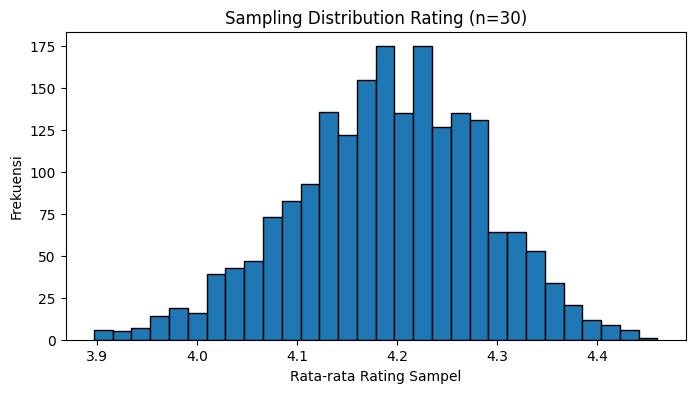


Ukuran sampel: 300
SE Empiris: 0.03058
SE Teori: 0.02974


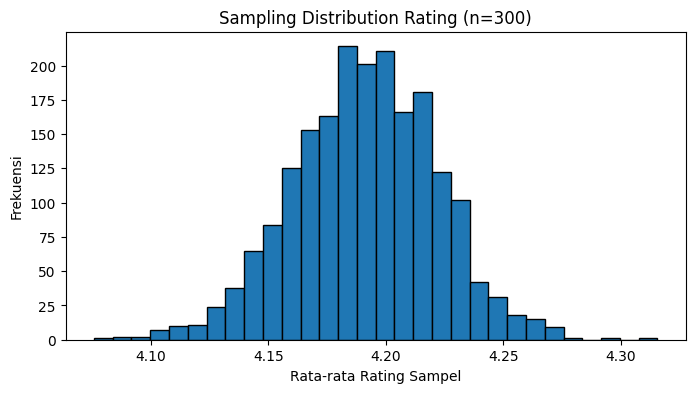


Ukuran sampel: 3000
SE Empiris: 0.00937
SE Teori: 0.00941


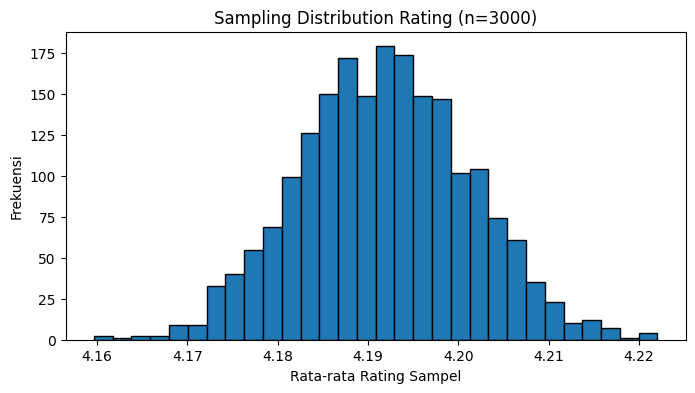

,Ukuran Sampel,SE Empiris,SE Teori
0,30,0.094479,0.094061
1,300,0.030585,0.029745
2,3000,0.009368,0.009406


In [3]:
# ==========================================
# 1. SAMPLING DISTRIBUTION
# ==========================================

print("SAMPLING DISTRIBUTION RATING")

sampling_results = []

for n in [30, 300, 3000]:

    means = rng.choice(
        pop,
        size=(2000, n),
        replace=True
    ).mean(axis=1)

    se_empiris = means.std()
    se_teori = pop.std() / np.sqrt(n)

    sampling_results.append({
        "Ukuran Sampel": n,
        "SE Empiris": se_empiris,
        "SE Teori": se_teori
    })

    print(f"\nUkuran sampel: {n}")
    print("SE Empiris:", round(se_empiris, 5))
    print("SE Teori:", round(se_teori, 5))

    plt.figure(figsize=(8, 4))
    plt.hist(means, bins=30, edgecolor="black")
    plt.title(f"Sampling Distribution Rating (n={n})")
    plt.xlabel("Rata-rata Rating Sampel")
    plt.ylabel("Frekuensi")
    plt.show()

sampling_df = pd.DataFrame(sampling_results)
display(sampling_df)

In [4]:
# ==========================================
# 2. CI RUMUS VS BOOTSTRAP
# ==========================================

# Selisih rata-rata sampel
mean_diff = x1.mean() - x2.mean()

# Welch's t-test
test_result = stats.ttest_ind(
    x1,
    x2,
    equal_var=False
)

# Standard error Welch
se_diff = np.sqrt(
    x1.var(ddof=1) / len(x1) +
    x2.var(ddof=1) / len(x2)
)

# Derajat kebebasan Welch-Satterthwaite
a = x1.var(ddof=1) / len(x1)
b = x2.var(ddof=1) / len(x2)

df_welch = (a + b)**2 / (
    (a**2 / (len(x1)-1)) +
    (b**2 / (len(x2)-1))
)

# CI 95% menggunakan rumus Welch
t_critical = stats.t.ppf(0.975, df_welch)

ci_manual = (
    mean_diff - t_critical * se_diff,
    mean_diff + t_critical * se_diff
)

# Bootstrap CI
boot = []

for i in range(2000):
    sample1 = rng.choice(x1, size=len(x1), replace=True)
    sample2 = rng.choice(x2, size=len(x2), replace=True)

    boot_diff = sample1.mean() - sample2.mean()
    boot.append(boot_diff)

ci_bootstrap = np.percentile(boot, [2.5, 97.5])

print("CI 95% RUMUS WELCH")
print("Batas bawah:", round(ci_manual[0], 4))
print("Batas atas:", round(ci_manual[1], 4))

print("\nCI 95% BOOTSTRAP")
print("Batas bawah:", round(ci_bootstrap[0], 4))
print("Batas atas:", round(ci_bootstrap[1], 4))

print("\nSelisih rata-rata Free - Paid:",
      round(mean_diff, 4))

CI 95% RUMUS WELCH
Batas bawah: -0.124
Batas atas: -0.0368

CI 95% BOOTSTRAP
Batas bawah: -0.1237
Batas atas: -0.0341

Selisih rata-rata Free - Paid: -0.0804


In [5]:
# ==========================================
# 3. POWER ANALYSIS
# ==========================================

alpha = 0.05
target_power = 0.80
MDE = 0.1

# Pooled standard deviation
pooled_std = np.sqrt(
    (
        (len(x1) - 1) * x1.var(ddof=1) +
        (len(x2) - 1) * x2.var(ddof=1)
    ) /
    (len(x1) + len(x2) - 2)
)

# Cohen's d berdasarkan MDE
effect_size = MDE / pooled_std

power_analysis = TTestIndPower()

required_n = power_analysis.solve_power(
    effect_size=effect_size,
    alpha=alpha,
    power=target_power,
    ratio=1,
    alternative="two-sided"
)

print("POWER ANALYSIS")
print("MDE:", MDE)
print("Pooled Standard Deviation:", round(pooled_std, 4))
print("Cohen's d:", round(effect_size, 4))
print("Alpha:", alpha)
print("Target Power:", target_power)
print("Kebutuhan sampel per kelompok:", int(np.ceil(required_n)))
print("Total kebutuhan sampel:", int(np.ceil(required_n)) * 2)
print("Sampel Free saat ini:", len(x1))
print("Sampel Paid saat ini:", len(x2))

POWER ANALYSIS
MDE: 0.1
Pooled Standard Deviation: 0.5148
Cohen's d: 0.1942
Alpha: 0.05
Target Power: 0.8
Kebutuhan sampel per kelompok: 418
Total kebutuhan sampel: 836
Sampel Free saat ini: 8719
Sampel Paid saat ini: 647


In [6]:
# ==========================================
# 4. REKOMENDASI SHIP OR NOT
# ==========================================

ci_low, ci_high = ci_bootstrap

print("REKOMENDASI SHIP OR NOT")
print("Selisih rata-rata:", round(mean_diff, 4))
print("CI Bootstrap:", ci_bootstrap)
print("Batas MDE:", MDE)

if ci_low > MDE:
    keputusan = "SHIP"
    alasan = (
        "Seluruh interval CI berada di atas MDE. "
        "Aplikasi Free memiliki rata-rata Rating lebih tinggi "
        "dengan perbedaan yang bermakna menurut batas MDE."
    )

elif ci_high < -MDE:
    keputusan = "SHIP"
    alasan = (
        "Seluruh interval CI berada di bawah -MDE. "
        "Aplikasi Paid memiliki rata-rata Rating lebih tinggi "
        "dengan perbedaan yang bermakna menurut batas MDE."
    )

elif ci_low > -MDE and ci_high < MDE:
    keputusan = "NOT SHIP"
    alasan = (
        "Seluruh interval CI berada di dalam batas -MDE sampai MDE. "
        "Perbedaan Rating diperkirakan terlalu kecil untuk dianggap "
        "bermakna secara bisnis."
    )

else:
    keputusan = "BELUM DAPAT DIPASTIKAN"
    alasan = (
        "Interval CI masih bersinggungan dengan batas MDE. "
        "Diperlukan data tambahan atau penelitian lanjutan."
    )

print("\nKEPUTUSAN:", keputusan)
print("ALASAN:", alasan)

REKOMENDASI SHIP OR NOT
Selisih rata-rata: -0.0804
CI Bootstrap: [-0.12371694 -0.03405138]
Batas MDE: 0.1

KEPUTUSAN: BELUM DAPAT DIPASTIKAN
ALASAN: Interval CI masih bersinggungan dengan batas MDE. Diperlukan data tambahan atau penelitian lanjutan.


In [7]:
# ==========================================
# RINGKASAN MILESTONE 3
# ==========================================

ringkasan_m3 = pd.DataFrame({
    "Komponen": [
        "Sampling Distribution n=30",
        "Sampling Distribution n=300",
        "Sampling Distribution n=3000",
        "CI Rumus Welch",
        "CI Bootstrap",
        "Power Analysis",
        "Rekomendasi"
    ],
    "Hasil": [
        f"SE = {sampling_results[0]['SE Empiris']:.5f}",
        f"SE = {sampling_results[1]['SE Empiris']:.5f}",
        f"SE = {sampling_results[2]['SE Empiris']:.5f}",
        f"{ci_manual[0]:.4f} sampai {ci_manual[1]:.4f}",
        f"{ci_bootstrap[0]:.4f} sampai {ci_bootstrap[1]:.4f}",
        f"{int(np.ceil(required_n))} sampel per kelompok",
        keputusan
    ]
})

display(ringkasan_m3)

,Komponen,Hasil
0,Sampling Distribution n=30,SE = 0.09448
1,Sampling Distribution n=300,SE = 0.03058
2,Sampling Distribution n=3000,SE = 0.00937
3,CI Rumus Welch,-0.1240 sampai -0.0368
4,CI Bootstrap,-0.1237 sampai -0.0341
5,Power Analysis,418 sampel per kelompok
6,Rekomendasi,BELUM DAPAT DIPASTIKAN


## H.2 Pertanyaan Refleksi

1. **Sampling distribution**: Jelaskan dengan bahasa sendiri perbedaan *distribusi sampel* dan *sampling distribution*. Mengapa sampling distribution retensi-7 berbentuk Normal padahal datanya hanya 0 dan 1?

2. **Bootstrap**: Bootstrap CI selisih retensi-7 hampir sama dengan CI rumus. Lalu kapan bootstrap benar-benar dibutuhkan? Berikan satu contoh metrik dari dunia aplikasi (e-commerce, ojek online, game) yang tidak punya rumus SE sederhana.

3. **Power**: Seorang PM berkata, "Retensi-1 tidak signifikan, jadi pemindahan gerbang tidak berpengaruh ke retensi-1." Tanggapi pernyataan ini dengan hasil Bagian F.

4. **SRM**: Jika SRM check menghasilkan p < 0.001, mengapa analisis z-test sebaiknya dihentikan dulu? Sebutkan 2 kemungkinan penyebab teknis SRM.

5. **Peeking**: Tim Anda ingin memantau dashboard A/B setiap hari. Bagaimana cara melakukannya tanpa terjebak peeking problem?

### ✏️ Jawaban Anda:

**1.** Distribusi sampel adalah sebaran data yang diperoleh dari satu kali pengambilan sampel dari populasi. Sementara itu, sampling distribution adalah distribusi dari suatu nilai statistik, misalnya rata-rata, yang dihitung berulang kali dari banyak sampel berbeda.

Sampling distribution retensi-7 dapat berbentuk Normal meskipun data aslinya hanya bernilai 0 dan 1 karena adanya Central Limit Theorem (CLT). Ketika pengambilan sampel dilakukan berulang kali dengan ukuran sampel yang cukup besar, distribusi rata-rata sampel akan cenderung mendekati distribusi Normal. Jadi, yang berbentuk Normal adalah distribusi rata-rata sampelnya, bukan data retensi-7 aslinya.

**2.** Bootstrap CI bisa menghasilkan nilai yang hampir sama dengan CI rumus karena kedua metode digunakan untuk memperkirakan ketidakpastian suatu statistik. Namun, bootstrap lebih dibutuhkan ketika metrik yang dianalisis memiliki distribusi tidak normal, bentuk yang kompleks, atau tidak memiliki rumus standar error yang mudah digunakan.

Contohnya adalah rata-rata nilai transaksi pelanggan (Average Order Value/AOV) pada aplikasi e-commerce. Nilai transaksi biasanya memiliki distribusi yang tidak simetris karena sebagian kecil pelanggan dapat melakukan transaksi dengan nominal sangat besar. Dalam kondisi tersebut, bootstrap dapat digunakan untuk memperkirakan confidence interval tanpa harus bergantung pada asumsi distribusi Normal.

**3.** Menurut saya, pernyataan PM tersebut belum tentu benar. Hasil yang tidak signifikan bukan berarti pemindahan gerbang tidak berpengaruh sama sekali terhadap retensi-1. Hasil tersebut hanya menunjukkan bahwa bukti yang tersedia belum cukup untuk menyatakan adanya perbedaan yang signifikan secara statistik.

Berdasarkan hasil Bagian F, keputusan harus mempertimbangkan nilai p-value, statistical power, dan minimum detectable effect (MDE). Jika power pengujian rendah, ada kemungkinan pengujian belum mampu mendeteksi efek yang sebenarnya ada. Oleh karena itu, PM sebaiknya tidak langsung menyimpulkan bahwa perubahan tidak berpengaruh, tetapi perlu mempertimbangkan apakah ukuran sampel sudah cukup dan apakah confidence interval masih mencakup efek yang bermakna.

**4.** Jika hasil SRM check menghasilkan p-value kurang dari 0,001, analisis z-test sebaiknya dihentikan sementara karena terdapat indikasi bahwa pembagian pengguna ke dalam grup eksperimen tidak sesuai dengan rasio yang telah ditentukan.

Kondisi ini dapat menyebabkan hasil eksperimen menjadi bias karena kedua grup mungkin tidak terbentuk secara seimbang. Dua kemungkinan penyebab teknis SRM adalah:
1. Kesalahan pada randomisasi pengguna, misalnya sistem pembagian grup tidak berjalan dengan benar sehingga sebagian besar pengguna masuk ke satu grup.
2. Masalah pada pencatatan data atau logging, misalnya sebagian aktivitas pengguna tidak tercatat atau data dari salah satu grup gagal dikirim ke server.
Sebelum melanjutkan analisis, tim perlu memeriksa sistem randomisasi dan memastikan pencatatan data pada kedua grup berjalan dengan benar.

**5.** Untuk memantau dashboard A/B testing setiap hari tanpa terjebak peeking problem, tim perlu menetapkan aturan pengujian sejak awal. Misalnya, menentukan ukuran sampel minimum, durasi eksperimen, tingkat signifikansi, dan kapan hasil akhir akan dievaluasi.

Dashboard tetap boleh dipantau setiap hari untuk melihat kondisi teknis, seperti jumlah pengguna, error, dan SRM. Namun, tim tidak boleh terus-menerus menghentikan eksperimen hanya karena nilai p-value sudah terlihat signifikan.

Jika memang membutuhkan pemantauan signifikansi secara berulang, tim dapat menggunakan metode sequential testing atau alpha spending yang memang dirancang untuk pengujian berulang. Dengan begitu, hasil eksperimen tetap dapat dievaluasi secara lebih terkontrol.


## H.3 Checklist Submit

### Praktikum (notebook ini)
- [ ] Semua cell berjalan tanpa error
- [ ] Tabel SE empiris vs teori untuk n = 100, 1.000, 10.000
- [ ] CI Wald vs Wilson + CI selisih retensi
- [ ] Bootstrap CI selisih retensi-7 & median ronde
- [ ] SRM check + z-test kedua metrik
- [ ] Kurva sample size & power retensi-1
- [ ] Simulasi peeking (false positive ≈ 5% vs jauh lebih tinggi)
- [ ] 5 pertanyaan refleksi dijawab

### Milestone 3 (notebook projek Anda)
- [ ] Simulasi sampling distribution 1 metrik utama
- [ ] CI rumus + bootstrap CI, dibandingkan
- [ ] CI selisih 2 grup penting
- [ ] Power analysis untuk MDE pilihan + evaluasi kecukupan data
- [ ] Rekomendasi keputusan + catatan risiko
- [ ] README diperbarui, commit: `"Milestone 3: sampling distribution & CI"`
- [ ] Link GitHub dikumpulkan via LMS **sebelum Modul 12**

---

## 🎓 Selamat! Anda Berhasil...

✅ Membuktikan SE = σ/√n lewat simulasi
✅ Menghitung CI proporsi, selisih, dan bootstrap CI
✅ Menentukan sample size dengan power analysis
✅ Mendeteksi SRM dan membuktikan bahaya peeking
✅ Membuat rekomendasi keputusan dari eksperimen 90.000 pemain

## 📚 Bacaan Lanjutan
- **Kohavi, R., Tang, D., & Xu, Y.** (2020). *Trustworthy Online Controlled Experiments: A Practical Guide to A/B Testing*. Cambridge University Press.
- **Bruce, P.** (2020). *Practical Statistics for Data Scientists*, Ch. 2 (Sampling Distribution & Bootstrap).
- **Efron, B. & Tibshirani, R.** (1993). *An Introduction to the Bootstrap*.

---

*Notebook by: Prodi Teknik Informatika · Uniska MAB Banjarmasin · Edisi 2026*
